In [2]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from cmap import Colormap

from spectraderma_processor import SpectraDermaProcessor

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [3]:
# Initialize processor
processor = SpectraDermaProcessor(sample_rate=50.0)

# 555S2

In [45]:
processor.load_data('../data/spectraderama_data_2025-04-02_sattac555S2.csv')
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).moving_average(window=300)

timestamp, channels_ma = processor.get_data()
timestamp = timestamp[::300]
channels_ma = channels_ma[::300]

c:\Users\y1hli\OneDrive - University of North Carolina at Chapel Hill\github\SpectraDerma\notebooks\..\spectraderma_processor.py:17: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(csv_path)


(0.0, 150.0)

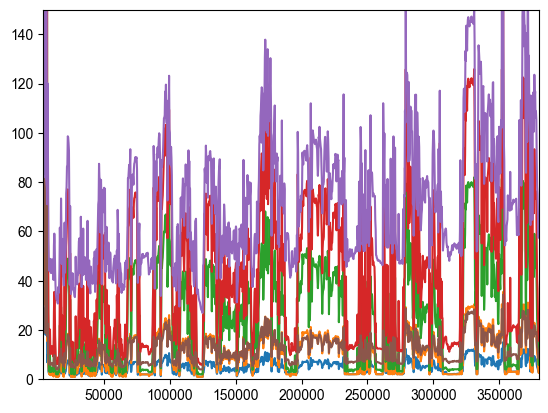

In [46]:
mode_b_start = 4000
mode_b_end = 380000

mode_b_region = (mode_b_start, mode_b_end)

plt.plot(timestamp, channels_ma)
plt.xlim(*mode_b_region)
plt.ylim(0, 150)

# 520S2

In [ ]:
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).moving_average(window=300)

timestamp, channels_ma = processor.get_data()

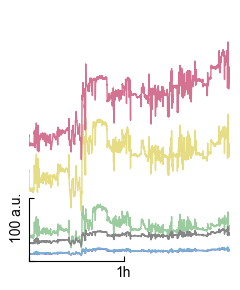

In [64]:
mode_b_start = 7800
mode_b_end = 390000

mode_b_region = (mode_b_start, mode_b_end)
amplitude_limits = (0, 400)

fig, ax = plt.subplots(figsize=(2.5, 3))

for i in range(channels_ma.shape[1]):
    plt.plot(timestamp, channels_ma[:, i], color=colors[i], linewidth=1)
    plt.xlim(*mode_b_region)
    plt.ylim(0, 400)

ax.spines['bottom'].set_bounds(mode_b_start, mode_b_start + 50 * 3600)
ax.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 100)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xticks([mode_b_start, mode_b_start + 50 * 3600])
ax.set_xticklabels(['', '1h'])
ax.set_yticks([amplitude_limits[0], amplitude_limits[0] + 100])
ax.set_yticklabels(['', '100 a.u.'], rotation=90)

ax.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_b_sample.png', dpi=600, bbox_inches='tight')
plt.show()

## MODE B PCA

### Acquire gold standard

In [65]:
original_timestamp = pd.read_csv('../data/spectraderama_data_2025-03-25_sattac520S2.csv')['id']
original_timestamp = pd.to_datetime(original_timestamp, format='%Y-%m-%dT%H:%M:%S.%fZ')
print(original_timestamp.head())

gold_standard = pd.read_csv('../data/SatTAC_metadata.csv')
gold_standard_timestamp = gold_standard['lab_session_timepoints_timestamp']
gold_standard_data = gold_standard['brac']
gold_standard_520 = gold_standard[gold_standard['record_id'] == 520].copy()

# Convert gold standard timestamps to datetime
gold_standard_520['datetime'] = pd.to_datetime(gold_standard_520['lab_session_timepoints_timestamp'], format='%m/%d/%y %H:%M')
spectra_start = original_timestamp - pd.Timedelta(hours=4)

# Calculate seconds from spectra start
gold_standard_520['seconds_from_start'] = (gold_standard_520['datetime'] - spectra_start).dt.total_seconds()
gold_standard_520.loc[gold_standard_520.index[0], 'seconds_from_start'] = 0

# Print the aligned timestamps
print("Gold standard data for subject 520:")
print(gold_standard_520[['timepoint', 'datetime', 'seconds_from_start', 'brac']].to_string(index=False))

0   2025-03-25 14:20:56.399
1   2025-03-25 14:20:56.399
2   2025-03-25 14:20:56.399
3   2025-03-25 14:20:56.399
4   2025-03-25 14:20:56.399
Name: id, dtype: datetime64[ns]
Gold standard data for subject 520:
 timepoint            datetime  seconds_from_start  brac
         1 2025-03-25 10:09:00               0.000 0.000
         2 2025-03-25 11:45:00            5042.612 0.028
         3 2025-03-25 12:00:00            5942.612 0.037
         4 2025-03-25 12:31:00            7802.612 0.046
         5 2025-03-25 12:44:00            8582.612 0.064
         6 2025-03-25 13:00:00            9542.612 0.069
         7 2025-03-25 13:13:00           10322.612 0.070


In [66]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

timestamp_mode_b = timestamp[(timestamp >= mode_b_start) & (timestamp <= mode_b_end)]
channels_mode_b = channels_ma[(timestamp >= mode_b_start) & (timestamp <= mode_b_end)]

# Standardize the data before PCA
scaler = StandardScaler()
channels_mode_b_scaled = scaler.fit_transform(channels_mode_b)

# Apply PCA
pca_520 = PCA()
pca_components_520 = pca_520.fit_transform(channels_mode_b_scaled)

### preprocessing both spectraderma and gold standard data 

In [67]:
from scipy.interpolate import PchipInterpolator

window_size = 4000
hop_size = 4000

# Apply windowed average to PCA components
pca_components_smooth = []
timestamps_smooth = []

for i in range(0, len(pca_components_520) - window_size + 1, hop_size):
    window_data = pca_components_520[i:i + window_size]
    window_mean = np.mean(window_data, axis=0)
    pca_components_smooth.append(window_mean)
    # Use the center timestamp of the window
    timestamps_smooth.append(timestamp_mode_b[i + window_size // 2])

y1_spec = np.array(pca_components_smooth)[:, 0]
y2_spec = np.array(pca_components_smooth)[:, 1]
t_spec = np.array(timestamps_smooth)

gold_standard_hours = gold_standard_520['seconds_from_start'] / 3600
t_brac = np.linspace(gold_standard_hours.iloc[0], gold_standard_hours.iloc[-1], num=100)
brac_interp_func = PchipInterpolator(gold_standard_hours, gold_standard_520['brac'])
y_brac = brac_interp_func(t_brac)

t_spec = (t_spec - timestamp_mode_b[0]) / (3600 * 30)

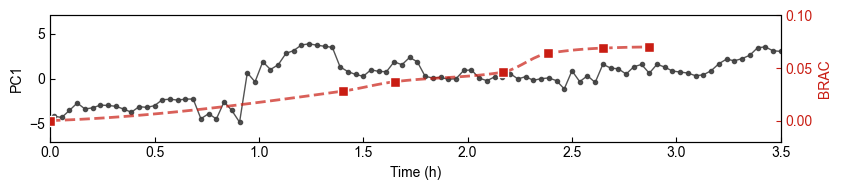

In [68]:
pc1_var_pct = pca_520.explained_variance_ratio_[0] * 100

fig, ax1 = plt.subplots(figsize=(8.6, 2))
ax1_color = Colormap('colorbrewer:Greys')(0.8).hex
ax1.plot(t_spec, y1_spec, marker='o', markersize=3, color=ax1_color, alpha=0.9, linewidth=1)

ax1.set_xlim(0, t_spec[-1])
ax1.set_ylim(-7, 7)

ax1.set_xlabel('Time (h)')
ax1.set_ylabel('PC1')
ax1.tick_params(direction='in')

ax2 = ax1.twinx()
ax2_color = Colormap('colorbrewer:OrRd')(0.8).hex
ax2.plot(t_brac, y_brac,
         color=ax2_color, linestyle='--', alpha=0.7, linewidth=2)
ax2.scatter(gold_standard_hours, gold_standard_520['brac'],
            color=ax2_color, s=50, marker='s',
            zorder=10, edgecolors='white', linewidth=1)
ax2.set_ylabel('BRAC', color=ax2_color)
ax2.set_ylim(-0.02, 0.1)

ax2.tick_params(axis='y', color=ax2_color, labelcolor=ax2_color, direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig3/mode_b_pca_pc1.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

In [69]:
from scipy import stats

# restrict to overlapping time range
t0 = max(t_spec.min(), t_brac.min())
t1 = min(t_spec.max(), t_brac.max())
ms = (t_spec >= t0) & (t_spec <= t1)
mb = (t_brac >= t0) & (t_brac <= t1)
t_spec = t_spec[ms]
y1_spec = y1_spec[ms]
y2_spec = y2_spec[ms]

t_brac = t_brac[mb]
y_brac = y_brac[mb]

# resample BRAC to SpectraDerma timestamps
y_brac_on_spec = np.interp(t_spec, t_brac, y_brac)

# compute Pearson correlation
pearson_r = np.corrcoef(y1_spec, y_brac_on_spec)[0, 1]
spearman_rho = stats.spearmanr(y1_spec, y_brac_on_spec)[0]
mx, my = y1_spec.mean(), y_brac_on_spec.mean()
vx, vy = y1_spec.var(ddof=1), y_brac_on_spec.var(ddof=1)
cov = np.cov(y1_spec, y_brac_on_spec, ddof=1)[0, 1]
ccc = (2*cov) / (vx + vy + (mx - my)**2)

print(f"Pearson r  : {pearson_r:.3f}")
print(f"Spearman ρ : {spearman_rho:.3f}")
print(f"CCC        : {ccc:.3f}")

Pearson r  : 0.537
Spearman ρ : 0.528
CCC        : 0.010


### NOTE: fig3 axis position

In [70]:
from matplotlib.transforms import Bbox
from copy import deepcopy

pos_ax = Bbox([[0.125, 0.10999999999999999], [0.9, 0.88]])

### Correlation

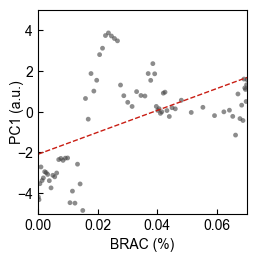

In [71]:
plt.figure(figsize=(2.7, 2.65))
plt.scatter(y_brac_on_spec, y1_spec, s=12, alpha=0.6, color=ax1_color, edgecolors='none')
# least-squares fit for visual guide
m, b = np.polyfit(y_brac_on_spec, y1_spec, 1)
xg = np.linspace(np.min(y_brac_on_spec), np.max(y_brac_on_spec), 100)

plt.plot(xg, m*xg + b, lw=1, ls='--', color=ax2_color)

plt.xlabel('BRAC (%)')
plt.ylabel('PC1 (a.u.)', labelpad=-5)

plt.xlim(0, 0.07)
plt.ylim(-5, 5)

plt.tick_params(axis='both', which='both', direction='in')

ax = plt.gca()
ax.set_position(pos_ax)

# plt.savefig('../figures/fig3/mode_b_corr.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

### PCA characterization

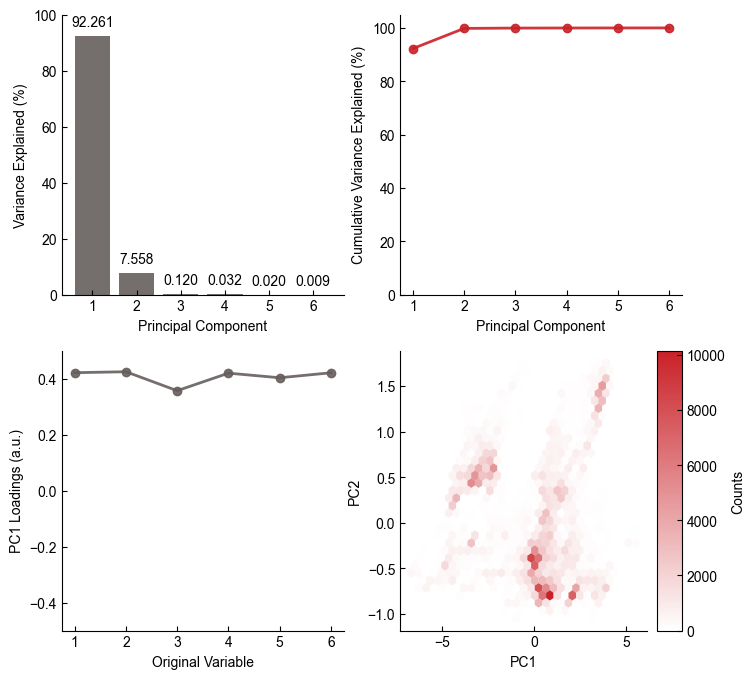

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(8, 8))

# Scree plot
ax1 = axes[0, 0]
bars = ax1.bar(range(1, len(variance) + 1), variance, color='#655e5c', alpha=0.9)
ax1.bar_label(bars, fmt='%.3f', padding=5)
ax1.set_ylim(0, 100)
ax1.set_xticks(range(1, len(variance) + 1))
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Variance Explained (%)')

# Cumulative variance plot
ax2 = axes[0, 1]
ax2.plot(range(1, len(cumulative_var) + 1), cumulative_var, marker='o', color='#c92127', alpha=0.9, linewidth=2)
ax2.set_ylim(0, 105)
ax2.set_xticks(range(1, len(cumulative_var) + 1))
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Variance Explained (%)')

# Loadings for PC1
ax3 = axes[1, 0]
ax3.plot(range(1, len(loadings_pc1) + 1), loadings_pc1, marker='o', color='#655e5c', alpha=0.9, linewidth=2)
ax3.set_xticks(range(1, len(loadings_pc1) + 1))
ax3.set_xlabel('Original Variable')
ax3.set_ylabel('PC1 Loadings (a.u.)')
ax3.set_ylim(-0.5, 0.5)

# State space density
ax4 = axes[1, 1]
# Assuming you have your custom colormap, otherwise replace with 'Reds'
cmap = Colormap(['#ffffff', '#c92127']).to_mpl()

hb = ax4.hexbin(pca_components_520[:, 0], pca_components_520[:, 1], gridsize=30, cmap=cmap, mincnt=0, linewidths=0.1)
ax4.set_xlabel('PC1')
ax4.set_ylabel('PC2')

divider = make_axes_locatable(ax4)
cax = divider.append_axes("right", size="10%", pad=0.1)
cb = fig.colorbar(hb, cax=cax)
cb.set_label('Counts')
cb.ax.tick_params(direction='in')

for ax in axes.flatten():
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(direction='in')

plt.savefig('../figures/SI/figs4-pca_summary/mode_b_pca_summary.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

### PCA trajectory on time

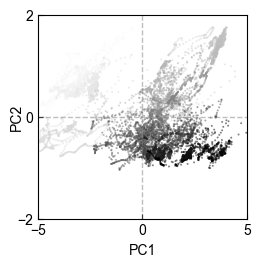

In [73]:
plt.figure(figsize=(2.7, 2.65))

# Calculate hours from start for coloring
time_hours = (timestamp_mode_b - timestamp_mode_b[0]) / (30 * 3600)  # Convert seconds to hours
time_hours_downsampled = time_hours[::30]

plt.scatter(pca_components_520[::30, 0], pca_components_520[::30, 1], 
            c=time_hours_downsampled, cmap='Grays',
            edgecolor='none',
            s=2, alpha=0.5)

plt.xlabel('PC1')
plt.ylabel('PC2', labelpad=-5)

# Add colorbar
# cbar = plt.colorbar()
# cbar.set_label('Hour', loc='bottom', rotation=0, labelpad=0)
# cbar.ax.yaxis.set_tick_params(length=0)

plt.xlim(-5, 5)
plt.ylim(-2, 2)

plt.xticks([-5, 0, 5])
plt.yticks([-2, 0, 2])

plt.tick_params(axis='both', which='both', direction='in')
plt.axhline(0, color='gray', lw=1, ls='--', alpha=0.5)
plt.axvline(0, color='gray', lw=1, ls='--', alpha=0.5)

ax = plt.gca()
ax.set_position(pos_ax)

# plt.savefig('../figures/fig3/mode_b_pca_traj.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

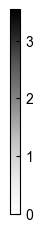

In [74]:
# Generate standalone colorbar for cell 21 (time-based coloring)
fig, ax = plt.subplots(figsize=(0.5, 2.65))

# Create a colorbar without plotting data
# Use the same time range as in cell 21
time_min = 0
time_max = (timestamp_mode_b[-1] - timestamp_mode_b[0]) / (30 * 3600)  # Convert to hours

# Create a scalar mappable for the colorbar
import matplotlib.cm as cm
import matplotlib.colors as mcolors

norm = mcolors.Normalize(vmin=time_min, vmax=time_max)
sm = cm.ScalarMappable(norm=norm, cmap='Grays')
sm.set_array([])

# Create the colorbar
cbar = plt.colorbar(sm, ax=ax, fraction=1.0, aspect=20)
cbar.ax.yaxis.set_tick_params(length=3, direction='in')

# Remove the main axes (we only want the colorbar)
ax.remove()

# Set the same position as the main plot for consistent height
fig.subplots_adjust(left=0.2, right=0.8, top=0.88, bottom=0.11)

# plt.savefig('../figures/fig3/mode_b_pca_traj_colorbar.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

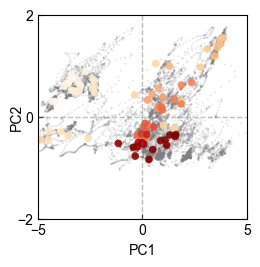

In [76]:
plt.figure(figsize=(2.7, 2.65))

plt.scatter(pca_components_520[::30, 0], pca_components_520[::30, 1], 
            c='gray',
            # c=np.arange(len(pca_components[::30, :])), cmap='Grays',
            edgecolor='none',
            s=2, alpha=0.2)

plt.scatter(y1_spec, y2_spec, 
            c=y_brac_on_spec, cmap=Colormap('colorbrewer:OrRd').to_mpl(), 
            edgecolor='none',
            s=30, alpha=0.9)

plt.xlabel('PC1')
plt.ylabel('PC2', labelpad=-5)

# Add colorbar
# cbar = plt.colorbar()
# cbar.set_label('BrAC', labelpad=-10)
# cbar.ax.yaxis.set_tick_params(length=0)
# cbar.set_ticks([0, 0.07])
# cbar.set_ticklabels([0, 7])

plt.xlim(-5, 5)
plt.ylim(-2, 2)

plt.xticks([-5, 0, 5])
plt.yticks([-2, 0, 2])

plt.tick_params(axis='both', which='both', direction='in')
plt.axhline(0, color='gray', lw=1, ls='--', alpha=0.5)
plt.axvline(0, color='gray', lw=1, ls='--', alpha=0.5)

ax = plt.gca()
ax.set_position(pos_ax)

# plt.savefig('../figures/fig3/mode_b_pca_traj_brac.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

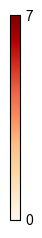

In [77]:
# Generate standalone colorbar for cell 23 (BRAC-based coloring)
fig, ax = plt.subplots(figsize=(0.5, 2.65))

# Create a colorbar without plotting data
# Use the same BRAC range as in cell 23
brac_min = 0
brac_max = 0.07  # As indicated in the commented colorbar code

# Create a scalar mappable for the colorbar
import matplotlib.cm as cm
import matplotlib.colors as mcolors

norm = mcolors.Normalize(vmin=brac_min, vmax=brac_max)
sm = cm.ScalarMappable(norm=norm, cmap=Colormap('colorbrewer:OrRd').to_mpl())
sm.set_array([])

# Create the colorbar
cbar = plt.colorbar(sm, ax=ax, fraction=1.0, aspect=20)
# cbar.set_label('BrAC (%)', rotation=90, labelpad=10)
cbar.ax.yaxis.set_tick_params(length=3, direction='in')

# Set custom ticks as indicated in the commented code (0 to 7, representing 0% to 0.07%)
cbar.set_ticks([0, 0.07])
cbar.set_ticklabels([0, 7])

# Remove the main axes (we only want the colorbar)
ax.remove()

# Set the same position as the main plot for consistent height
fig.subplots_adjust(left=0.2, right=0.8, top=0.88, bottom=0.11)

# plt.savefig('../figures/fig3/mode_b_pca_traj_brac_colorbar.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# 555S2

In [137]:
processor.load_data('../data/spectraderama_data_2025-04-02_sattac555S2.csv')
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).moving_average(window=300)

timestamp, channels_ma = processor.get_data()

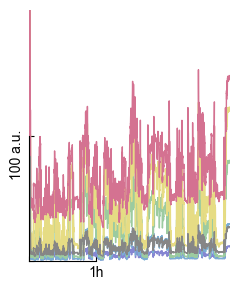

In [138]:
mode_b_start = 5000
mode_b_end = 330000

mode_b_region = (mode_b_start, mode_b_end)
amplitude_limits = (0, 400)

fig, ax = plt.subplots(figsize=(2.5, 3))

for i in range(channels_ma.shape[1]):
    plt.plot(timestamp, channels_ma[:, i], color=colors[i], linewidth=1)
    plt.xlim(*mode_b_region)
    plt.ylim(0, 200)

ax.spines['bottom'].set_bounds(mode_b_start, mode_b_start + 30 * 3600)
ax.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 100)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xticks([mode_b_start, mode_b_start + 30 * 3600])
ax.set_xticklabels(['', '1h'])
ax.set_yticks([amplitude_limits[0], amplitude_limits[0] + 100])
ax.set_yticklabels(['', '100 a.u.'], rotation=90)

ax.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
plt.show()

## MODE B PCA

### Acquire gold standard

In [140]:
original_timestamp_555 = pd.read_csv('../data/spectraderama_data_2025-04-02_sattac555S2.csv')['id']
original_timestamp_555 = pd.to_datetime(original_timestamp_555, format='%Y-%m-%dT%H:%M:%S.%fZ')
print(original_timestamp_555.head())

gold_standard = pd.read_csv('../data/SatTAC_metadata.csv')
gold_standard_timestamp = gold_standard['lab_session_timepoints_timestamp']
gold_standard_data = gold_standard['brac']
gold_standard_555 = gold_standard[np.logical_and(gold_standard['record_id'] == 555, gold_standard['session'] == 2)].copy()

# Convert gold standard timestamps to datetime
gold_standard_555['datetime'] = pd.to_datetime(gold_standard_555['lab_session_timepoints_timestamp'], format='%m/%d/%y %H:%M')
spectra_start_555 = original_timestamp_555 - pd.Timedelta(hours=4)

# Calculate seconds from spectra start
gold_standard_555['seconds_from_start'] = (gold_standard_555['datetime'] - spectra_start_555).dt.total_seconds()
gold_standard_555.loc[gold_standard_555.index[0], 'seconds_from_start'] = 0

# Print the aligned timestamps
print("Gold standard data for subject 555:")
print(gold_standard_555[['timepoint', 'datetime', 'seconds_from_start', 'brac']].to_string(index=False))

0   2025-04-02 13:58:02.657
1   2025-04-02 13:58:02.657
2   2025-04-02 13:58:02.657
3   2025-04-02 13:58:02.657
4   2025-04-02 13:58:02.657
Name: id, dtype: datetime64[ns]
Gold standard data for subject 555:
 timepoint            datetime  seconds_from_start  brac
         1 2025-04-02 09:36:00               0.000 0.000
         2 2025-04-02 10:53:00            3295.341 0.032
         3 2025-04-02 11:32:00            5635.341 0.024
         4 2025-04-02 11:49:00            6655.341 0.018
         5 2025-04-02 12:02:00            7435.341 0.016
         6 2025-04-02 12:20:00            8515.341 0.013
         7 2025-04-02 12:35:00            9415.341 0.009


In [141]:
timestamp_mode_b_555 = timestamp[(timestamp >= mode_b_start) & (timestamp <= mode_b_end)]
channels_mode_b_555 = channels_ma[(timestamp >= mode_b_start) & (timestamp <= mode_b_end)]

# Standardize the data before PCA
scaler_555 = StandardScaler()
channels_mode_b_scaled_555 = scaler_555.fit_transform(channels_mode_b_555)

# Apply PCA
pca_555 = PCA()
pca_components_555 = pca_555.fit_transform(channels_mode_b_scaled_555)

### preprocessing both spectraderma and gold standard data

In [142]:
from scipy.interpolate import PchipInterpolator

window_size = 4000
hop_size = 4000

# Apply windowed average to PCA components
pca_components_smooth = []
timestamps_smooth = []

for i in range(0, len(pca_components_555) - window_size + 1, hop_size):
    window_data = pca_components_555[i:i + window_size]
    window_mean = np.mean(window_data, axis=0)
    pca_components_smooth.append(window_mean)
    # Use the center timestamp of the window
    timestamps_smooth.append(timestamp_mode_b_555[i + window_size // 2])

y1_spec = np.array(pca_components_smooth)[:, 0]
y2_spec = np.array(pca_components_smooth)[:, 1]
t_spec = np.array(timestamps_smooth)

gold_standard_hours = gold_standard_555['seconds_from_start'] / 3600
t_brac = np.linspace(gold_standard_hours.iloc[0], gold_standard_hours.iloc[-1], num=100)
brac_interp_func = PchipInterpolator(gold_standard_hours, gold_standard_555['brac'])
y_brac = brac_interp_func(t_brac)

t_spec = (t_spec - timestamp_mode_b_555[0]) / (3600 * 30)

# resample BRAC to SpectraDerma timestamps
y_brac_on_spec = np.interp(t_spec, t_brac, y_brac)

In [149]:
from matplotlib.transforms import Bbox

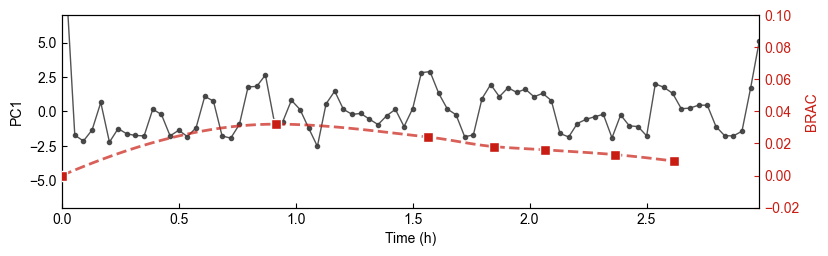

In [182]:
pc1_var_pct = pca_555.explained_variance_ratio_[0] * 100

fig, ax1 = plt.subplots(figsize=(9, 2.5))
ax1_color = Colormap('colorbrewer:Greys')(0.8).hex
ax1.plot(t_spec, y1_spec, marker='o', markersize=3, color=ax1_color, alpha=0.9, linewidth=1)

ax1.set_xlim(0, t_spec[-1])
ax1.set_ylim(-7, 7)

ax1.set_xlabel('Time (h)')
ax1.set_ylabel('PC1')
ax1.tick_params(direction='in')

ax2 = ax1.twinx()
ax2_color = Colormap('colorbrewer:OrRd')(0.8).hex
ax2.plot(t_brac, y_brac,
         color=ax2_color, linestyle='--', alpha=0.7, linewidth=2)
ax2.scatter(gold_standard_hours, gold_standard_555['brac'],
            color=ax2_color, s=50, marker='s',
            zorder=10, edgecolors='white', linewidth=1)
ax2.set_ylabel('BRAC', color=ax2_color)
ax2.set_ylim(-0.02, 0.1)

ax2.tick_params(axis='y', color=ax2_color, labelcolor=ax2_color, direction='in')

pos_ax = ax1.get_position()
plt.savefig('../figures/SI/figs3-placebo/mode_b_pca_pc1_placebo.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

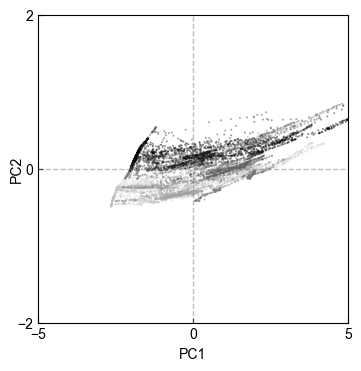

In [180]:
plt.figure(figsize=(4, 4))

# Calculate hours from start for coloring
time_hours_555 = (timestamp_mode_b_555 - timestamp_mode_b_555[0]) / (30 * 3600)  # Convert seconds to hours
time_hours_downsampled_555 = time_hours_555[::30]

plt.scatter(pca_components_555[::30, 0], pca_components_555[::30, 1], 
            c=time_hours_downsampled_555, cmap='Grays',
            edgecolor='none',
            s=2, alpha=0.5)

plt.xlabel('PC1')
plt.ylabel('PC2', labelpad=-5)

# Add colorbar
# cbar = plt.colorbar()
# cbar.set_label('Hour', loc='bottom', rotation=0, labelpad=0)
# cbar.ax.yaxis.set_tick_params(length=0)

plt.xlim(-5, 5)
plt.ylim(-2, 2)

plt.xticks([-5, 0, 5])
plt.yticks([-2, 0, 2])

plt.tick_params(axis='both', which='both', direction='in')
plt.axhline(0, color='gray', lw=1, ls='--', alpha=0.5)
plt.axvline(0, color='gray', lw=1, ls='--', alpha=0.5)

ax = plt.gca()
ax.set_position(Bbox.from_extents(pos_ax.x0, pos_ax.y0, pos_ax.x1, pos_ax.y1))

plt.savefig('../figures/SI/figs3-placebo/mode_b_pca_traj_placebo.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()